In [198]:
# Packages
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import time

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [199]:
# Download latest version.
path = kagglehub.dataset_download("danieltreiman/twitter-human-bots-dataset", output_dir="data/twitter-human-bots-dataset")
print("Path to dataset files:", path + "/" )

Path to dataset files: data/twitter-human-bots-dataset/


In [200]:
# Reads bot_detection_data.csv in the form of pandas data frame.
df = pd.read_csv("data/twitter-human-bots-dataset/twitter_human_bots_dataset.csv")
print(df.shape)

(37438, 23)


In [201]:
# Dropping all non-useful features. I am doing this for now, but we might have lost some valuable data doing this.
# Figuring out how we can use these these features can be a future improvement.
# The features that would be cool to include in the machine learning algorithm would be the images and the texts.
# For images we can use some kind of pretrained image neural network, for words we can use entropy.
columns_to_drop = [
    'Unnamed: 0',
    'created_at',
    'id',
    'lang',
    'location',
    'profile_background_image_url',
    'profile_image_url',
    'screen_name',
    'profile_image_path',
    'profile_background_image_path',
    'split',
]

df = df.drop(columns=columns_to_drop)

# Convert boolean attributes to numeric values (0 and 1).
boolean_columns = [
    'default_profile',
    'default_profile_image',
    'geo_enabled',
    'verified'
]

df[boolean_columns] = df[boolean_columns].astype(int)

# Binary flag: 0 = empty, 1 = has a description
df['description'] = df['description'].notna().astype(int)

# Encode account type as a binary label (1 = bot, 0 = human).
df['account_type'] = (df['account_type'] == 'bot').astype(int)

# Dropping all tuples that contain empty or null values. I am doing this for now, but we might have lost some valuable data doing this.
# Figuring out a better way to do this can be a future improvement.
df = df.dropna()
print(df.shape)

df.to_csv("data/twitter-human-bots-dataset/twitter-human-bots-dataset_processed.csv", index=False)

(37438, 12)


In [202]:
# Splitting into training and validation.
y = df['account_type']
x = df.drop(columns=['account_type'])

# List of features for later use
feature_list = list(x.columns)

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.3,
    random_state=42
)

In [203]:
# Random forest. Machine learning technique.
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    oob_score=True,
    criterion='entropy',
)

start = time.perf_counter()
rf_model.fit(x_train, y_train)
fit_time = time.perf_counter() - start

# Random forest results.
start = time.perf_counter()
rf_y_pred = rf_model.predict(x_test)
predict_time = time.perf_counter() - start

print("Random Forest")
print(classification_report(y_test, rf_y_pred))
print("Accuracy_score:", accuracy_score(y_test, rf_y_pred))
print(f"Training time: {fit_time:.4f} seconds")
print(f"Prediction time: {predict_time:.4f} seconds")
print(f"Total time: {fit_time + predict_time:.4f} seconds")

Random Forest
              precision    recall  f1-score   support

           0       0.89      0.94      0.91      7536
           1       0.86      0.76      0.81      3696

    accuracy                           0.88     11232
   macro avg       0.87      0.85      0.86     11232
weighted avg       0.88      0.88      0.88     11232

Accuracy_score: 0.8804309116809117
Training time: 3.3363 seconds
Prediction time: 0.0895 seconds
Total time: 3.4258 seconds


In [204]:
# MLP. Deep learning technique.
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

mlp = MLPClassifier(hidden_layer_sizes=(128, 128), max_iter=500, random_state=42)

start = time.perf_counter()
mlp.fit(x_train, y_train)
mlp_fit_time = time.perf_counter() - start

start = time.perf_counter()
y_pred = mlp.predict(x_test)
mlp_predict_time = time.perf_counter() - start

print("MLP")
print(classification_report(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Training time: {mlp_fit_time:.4f} seconds")
print(f"Prediction time: {mlp_predict_time:.4f} seconds")
print(f"Total time: {mlp_fit_time + mlp_predict_time:.4f} seconds")

MLP
              precision    recall  f1-score   support

           0       0.89      0.84      0.86      7536
           1       0.71      0.79      0.75      3696

    accuracy                           0.82     11232
   macro avg       0.80      0.82      0.81     11232
weighted avg       0.83      0.82      0.83     11232

Accuracy: 82.37%
Training time: 46.2492 seconds
Prediction time: 0.0073 seconds
Total time: 46.2564 seconds


In [205]:
# All the feature importance stuff.

# Get numerical feature importances
importances = list(rf_model.feature_importances_)
# List of tuples with variable and importance
feature_importances = [(feature, round(importance, 2)) for feature, importance in zip(feature_list, importances)]
# Sort the feature importances by most important first
feature_importances = sorted(feature_importances, key = lambda x: x[1], reverse = True)
# Print out the feature and importances 
[print('Variable: {:20} Importance: {}'.format(*pair)) for pair in feature_importances]

Variable: followers_count      Importance: 0.2
Variable: favourites_count     Importance: 0.19
Variable: friends_count        Importance: 0.14
Variable: statuses_count       Importance: 0.13
Variable: average_tweets_per_day Importance: 0.12
Variable: account_age_days     Importance: 0.12
Variable: verified             Importance: 0.04
Variable: default_profile      Importance: 0.02
Variable: geo_enabled          Importance: 0.02
Variable: description          Importance: 0.01
Variable: default_profile_image Importance: 0.0


[None, None, None, None, None, None, None, None, None, None, None]

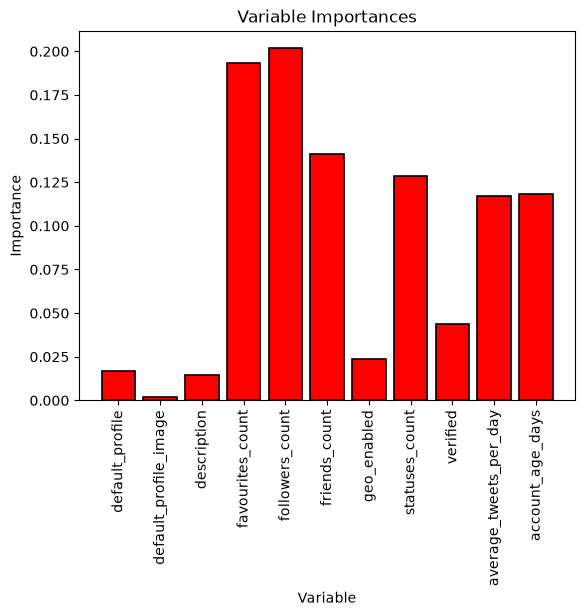

In [206]:
# list of x locations for plotting
x_values = list(range(len(importances)))
# Make a bar chart
plt.bar(x_values, importances, orientation = 'vertical', color = 'r', edgecolor = 'k', linewidth = 1.2)
# Tick labels for x axis
plt.xticks(x_values, feature_list, rotation='vertical')
# Axis labels and title
plt.ylabel('Importance'); plt.xlabel('Variable'); plt.title('Variable Importances');

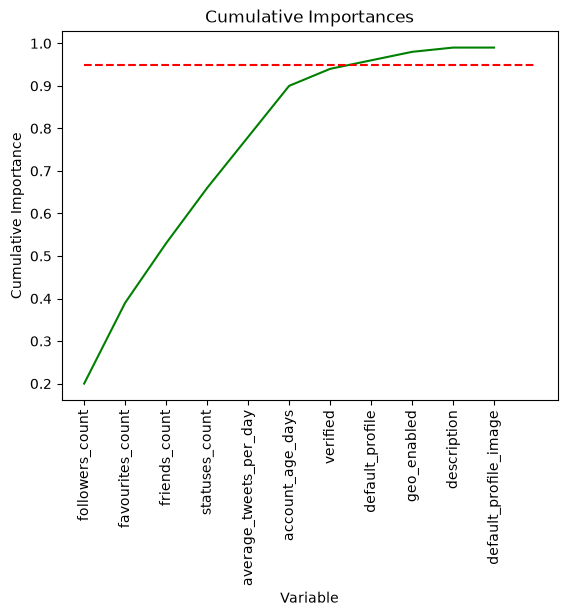

In [207]:
# List of features sorted from most to least important
sorted_importances = [importance[1] for importance in feature_importances]
sorted_features = [importance[0] for importance in feature_importances]
# Cumulative importances
cumulative_importances = np.cumsum(sorted_importances)
# Make a line graph
plt.plot(x_values, cumulative_importances, 'g-')
# Draw line at 95% of importance retained
plt.hlines(y = 0.95, xmin=0, xmax=len(sorted_importances), color = 'r', linestyles = 'dashed')
# Format x ticks and labels
plt.xticks(x_values, sorted_features, rotation = 'vertical')
# Axis labels and title
plt.xlabel('Variable'); plt.ylabel('Cumulative Importance'); plt.title('Cumulative Importances');

In [208]:
# Find number of features for cumulative importance of 95%
# Add 1 because Python is zero-indexed
print('Number of features for 95% importance:', np.where(cumulative_importances > 0.95)[0][0] + 1)

Number of features for 95% importance: 8


In [211]:
# Select features automatically: keep the smallest set whose cumulative
# importance reaches the threshold. Uses unrounded importances from rf_model.
IMPORTANCE_THRESHOLD = 0.95

importance_series = pd.Series(rf_model.feature_importances_, index=feature_list)
importance_series = importance_series.sort_values(ascending=False)

cumulative = importance_series.cumsum()
# Keep a feature if the running total before it is still below the threshold,
# which includes the feature that crosses the threshold.
selected_features = cumulative[cumulative.shift(fill_value=0) < IMPORTANCE_THRESHOLD].index.tolist()
print("Features used:", selected_features)

# Same rows as the original split (same data and random_state), reduced to the selected columns
x_train_2, x_test_2, y_train_2, y_test_2 = train_test_split(
    x[selected_features], y, test_size=0.3, random_state=42
)

# Random forest on the selected features
rf_model_2 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    oob_score=True,
    criterion='entropy',
)

start = time.perf_counter()
rf_model_2.fit(x_train_2, y_train_2)
fit_time = time.perf_counter() - start

start = time.perf_counter()
rf_y_pred_2 = rf_model_2.predict(x_test_2)
predict_time = time.perf_counter() - start

print("Random Forest (selected features)")
print(classification_report(y_test_2, rf_y_pred_2))
print(f"Accuracy: {accuracy_score(y_test_2, rf_y_pred_2) * 100:.2f}%")
print(f"Training time: {fit_time:.4f} seconds")
print(f"Prediction time: {predict_time:.4f} seconds")
print(f"Total time: {fit_time + predict_time:.4f} seconds")

Features used: ['followers_count', 'favourites_count', 'friends_count', 'statuses_count', 'account_age_days', 'average_tweets_per_day', 'verified']
Random Forest (selected features)
              precision    recall  f1-score   support

           0       0.89      0.94      0.91      7536
           1       0.87      0.76      0.81      3696

    accuracy                           0.88     11232
   macro avg       0.88      0.85      0.86     11232
weighted avg       0.88      0.88      0.88     11232

Accuracy: 88.10%
Training time: 3.4430 seconds
Prediction time: 0.0881 seconds
Total time: 3.5311 seconds
